<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [PDF Structure &amp; Rendering](https://github.com/Query-farm/vgi-pdf)

Pull tables, words with their positions, page geometry, form fields and metadata out of PDFs, and render pages to PNG.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-pdf/blob/main/notebooks/02_empty_fields_and_unavailable_documents.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-pdf/blob/main/notebooks/README.md)

## No form fields is different from an unreadable document

**Which documents can be routed to a reviewer without treating unavailable information as an empty answer?** Inspect a mixed, explicitly synthetic six-row batch using per-row PDF scalars. Keep readable empty maps, encryption, malformed bytes and missing input distinct, then apply a narrow required-AcroForm-field rule.

The inputs are unchanged released form/metadata/malformed test fixtures, the authored invoice from the first story, an intentionally encrypted derivative, and one SQL NULL input. They contain no real customer documents. PDF Author/Title values are document claims, not authenticated authorship; fixture metadata dates are not acquisition times.


### Choose one machine-readable field

`REQUIRED_FIELD` is **`full_name`** by default; use **`email`** for the experiment. The released form contains a populated `full_name` field and no `email` field. The policy asks only whether that named top-level AcroForm value is nonblank in an otherwise readable, unencrypted input.

“Ready for review” does not mean a valid application, identity verification or an acceptable email address. Printed text that resembles a field is not necessarily an AcroForm entry. No OCR or content validation is attempted.


In [1]:
REQUIRED_FIELD = "full_name"  # Experiment: "email". Reset: "full_name".


In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.35":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.35"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")


In [3]:
from IPython.display import display
from vgi_notebooks import check_runtime, connect, theme, prose, prepare

check_runtime()
prepare("pdf")
import pdf_example as example

example.validate_field(REQUIRED_FIELD)
example.verify_fixtures()
session = connect(globals())
theme()


### Use the registry to select the per-row interface

The worker's `functions` view describes both scalars and structure readers. Join the four planned intake operations to that actual registry and verify they are scalars. This choice preserves one result row per input, including NULL/unreadable documents. In contrast, structure readers return many rows and reject unreadable input; they are appropriate after intake, as in the first story.

The literal launcher runs public release v0.4.0 in a separate environment. This analysis reads only local files/bytes and never tries to decrypt the encrypted control.


In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'pdf' (TYPE vgi, LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-pdf@v0.4.0 vgi-pdf-worker');


,Success


In [5]:
%%sql operation_plan <<
CREATE TABLE planned_operations(name,purpose) AS VALUES
 ('page_count','Readable page population'),('is_encrypted','Separate encryption from unreadable bytes'),
 ('pdf_metadata','Inspect claimed document metadata'),('form_fields','Inspect machine-readable form values');
CREATE TABLE operation_plan AS
SELECT p.name,p.purpose,f.kind,f.category FROM planned_operations p
LEFT JOIN pdf.main.functions f USING(name);
SELECT * FROM operation_plan ORDER BY name;


In [6]:
display(operation_plan)
assert len(operation_plan)==4 and operation_plan.kind.eq("scalar").all()
prose(f"All **{len(operation_plan)} planned operations** are registered scalars. "
      "That supports a per-input inventory without losing the rows whose PDF information is unavailable.")


,name,purpose,kind,category
0,form_fields,Inspect machine-readable form values,scalar,Content
1,is_encrypted,Separate encryption from unreadable bytes,scalar,Metadata
2,page_count,Readable page population,scalar,Structure
3,pdf_metadata,Inspect claimed document metadata,scalar,Metadata


All **4 planned operations** are registered scalars. That supports a per-input inventory without losing the rows whose PDF information is unavailable.

### Keep every input and every missing result

Read the five local files once as BLOBs and add an explicit NULL input. Materialize each scalar output once. `is_encrypted = true` is a successful encryption detection even when page count, metadata and form extraction are unavailable without a password. `NULL` encryption is unknown, not false.

For readable PDFs, an empty metadata or form map is a valid result with cardinality zero. Avoid `coalesce(..., 0)` here: it would turn unavailable extraction into a claim that the document has no fields.


In [7]:
%%sql
CREATE TABLE inputs AS
SELECT parse_filename(filename) AS document_id,content
FROM read_blob(['fixtures/form.pdf','fixtures/meta.pdf','fixtures/invoice_variants.pdf',
                'fixtures/encrypted.pdf','fixtures/garbage.pdf'])
UNION ALL SELECT 'missing.pdf',NULL::BLOB;
CREATE TABLE assessed AS
SELECT document_id,content IS NOT NULL AS bytes_supplied,
       octet_length(content) AS input_bytes,sha256(content) AS input_sha256,
       pdf.main.page_count(content) AS page_count,pdf.main.is_encrypted(content) AS encrypted,
       pdf.main.pdf_metadata(content) AS metadata,pdf.main.form_fields(content) AS fields
FROM inputs;
CREATE TABLE inventory AS
SELECT *,cardinality(metadata) AS metadata_entries,cardinality(fields) AS form_field_count,
 CASE WHEN NOT bytes_supplied THEN 'Missing input'
      WHEN encrypted IS TRUE THEN 'Encrypted'
      WHEN page_count IS NULL THEN 'Unreadable bytes'
      ELSE 'Readable' END AS availability,
 CASE document_id WHEN 'form.pdf' THEN 1 WHEN 'meta.pdf' THEN 2 WHEN 'invoice_variants.pdf' THEN 3
      WHEN 'encrypted.pdf' THEN 4 WHEN 'garbage.pdf' THEN 5 ELSE 6 END AS document_order,
 CASE document_id WHEN 'form.pdf' THEN 'Filled form' WHEN 'meta.pdf' THEN 'Metadata only'
      WHEN 'invoice_variants.pdf' THEN 'Invoice' WHEN 'encrypted.pdf' THEN 'Encrypted'
      WHEN 'garbage.pdf' THEN 'Malformed' ELSE 'Missing' END AS document_label
FROM assessed;


,Count


In [8]:
%%sql
SELECT count(*) AS input_rows,count(input_sha256) AS supplied_payloads,sum(input_bytes) AS supplied_bytes,
       sha256(string_agg(document_id||':'||coalesce(input_sha256,'NULL'), '|' ORDER BY document_id)) AS input_fingerprint
FROM assessed;


,input_rows,supplied_payloads,supplied_bytes,input_fingerprint
0,6,5,7979.0,94ec3a512da9fa762776171aec9369b3585d56b8eee62c...


In [9]:
%%sql inventory_frame <<
SELECT document_label,input_bytes,page_count,encrypted,metadata_entries,form_field_count,availability
FROM inventory ORDER BY document_order;


In [10]:
display(inventory_frame)
readable=int(inventory_frame.availability.eq("Readable").sum())
prose(f"All **{len(inventory_frame)} inputs** remain visible; **{readable} are readable**. "
      "The filled form has zero metadata entries, and the metadata-only PDF has zero form fields: both are valid empty maps. "
      "The encrypted, malformed and missing controls have unavailable extraction maps, shown as NULL rather than zero.")


,document_label,input_bytes,page_count,encrypted,metadata_entries,form_field_count,availability
0,Filled form,741,1,False,0,1,Readable
1,Metadata only,1382,1,False,8,0,Readable
2,Invoice,3371,2,False,8,0,Readable
3,Encrypted,2440,<NA>,True,<NA>,<NA>,Encrypted
4,Malformed,45,<NA>,<NA>,<NA>,<NA>,Unreadable bytes
5,Missing,<NA>,<NA>,<NA>,<NA>,<NA>,Missing input


All **6 inputs** remain visible; **3 are readable**. The filled form has zero metadata entries, and the metadata-only PDF has zero form fields: both are valid empty maps. The encrypted, malformed and missing controls have unavailable extraction maps, shown as NULL rather than zero.

### Apply a transparent review rule

Route unreadable, encrypted and missing inputs before looking at the field. For readable inputs, inspect only the selected top-level AcroForm value after trimming whitespace. Keep all route categories in the summary, including those with zero documents.

The metadata Author and form value are independent fields: a document claiming Author “Ada Lovelace” does not thereby have a populated `full_name` form field. The following result makes that distinction visible.


In [11]:
%%sql review_rows <<
CREATE TABLE review_rows AS
SELECT document_id,document_label,document_order,availability,
       metadata['Author'] AS claimed_author,fields['{{ REQUIRED_FIELD }}'] AS selected_form_value,
 CASE WHEN availability<>'Readable' THEN availability
      WHEN nullif(trim(fields['{{ REQUIRED_FIELD }}']),'') IS NULL THEN 'Field absent or blank'
      ELSE 'Ready for review' END AS route
FROM inventory;
SELECT document_label,claimed_author,selected_form_value,route FROM review_rows ORDER BY document_order;


In [12]:
%%sql route_counts <<
CREATE TABLE route_counts AS
SELECT p.ordinal,p.route,count(r.document_id) AS documents
FROM (VALUES(1,'Ready for review'),(2,'Field absent or blank'),(3,'Encrypted'),
            (4,'Unreadable bytes'),(5,'Missing input')) p(ordinal,route)
LEFT JOIN review_rows r USING(route) GROUP BY p.ordinal,p.route;
SELECT * FROM route_counts ORDER BY ordinal;


In [13]:
display(review_rows)
display(route_counts)
ready=int(route_counts.loc[route_counts.route=="Ready for review","documents"].iloc[0])
prose(f"With required field **{REQUIRED_FIELD}**, **{ready} of 6 inputs** are ready for human review under this narrow rule. "
      f"All **{int(route_counts.documents.sum())} inputs** remain accounted for. "
      "A zero candidate count is a policy result; it does not erase readable PDFs or turn unknown extraction into an empty map.")


,document_label,claimed_author,selected_form_value,route
0,Filled form,None,Ada Lovelace,Ready for review
1,Metadata only,Ada Lovelace,None,Field absent or blank
2,Invoice,Query.Farm notebook fixture,None,Field absent or blank
3,Encrypted,None,None,Encrypted
4,Malformed,None,None,Unreadable bytes
5,Missing,None,None,Missing input


,ordinal,route,documents
0,1,Ready for review,1
1,2,Field absent or blank,2
2,3,Encrypted,1
3,4,Unreadable bytes,1
4,5,Missing input,1


With required field **full_name**, **1 of 6 inputs** are ready for human review under this narrow rule. All **6 inputs** remain accounted for. A zero candidate count is a policy result; it does not erase readable PDFs or turn unknown extraction into an empty map.

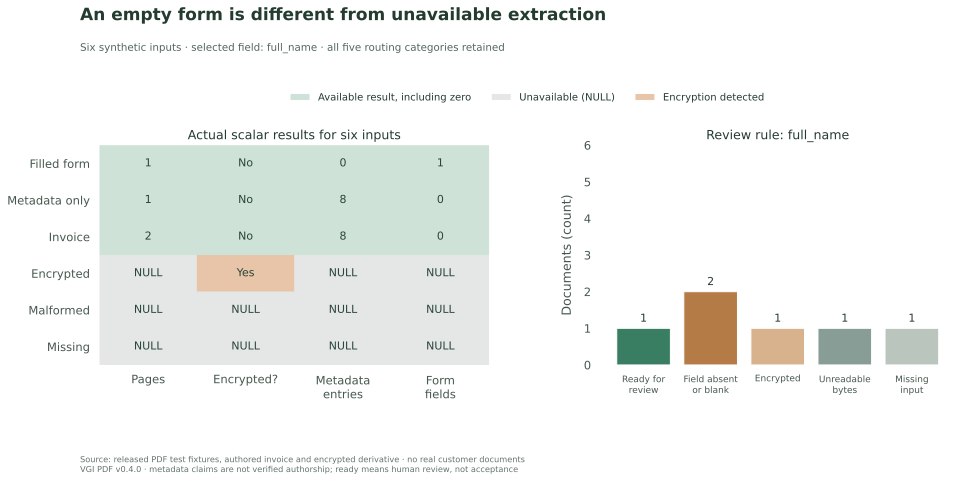

In [14]:
example.intake_accounting(inventory_frame, route_counts, REQUIRED_FIELD)


### Check availability and routing independently

Reconcile all six input identities and five supplied byte payloads, readable page totals, the true encryption control, NULL malformed/missing outputs and valid empty maps. Every row must receive exactly one route. The required field changes routing; it does not change the input bytes or scalar inventory.


In [15]:
%%sql checks <<
SELECT 'six unique inputs retained' AS check_name,(SELECT count(*)=6 AND count(DISTINCT document_id)=6 FROM inventory) AS passed
UNION ALL SELECT 'five supplied byte payloads',(SELECT count(input_sha256)=5 AND count(input_bytes)=5 FROM inventory)
UNION ALL SELECT 'planned operations are four scalars',(SELECT count(*)=4 AND bool_and(kind='scalar') FROM operation_plan)
UNION ALL SELECT 'three readable inputs contain four pages',(SELECT count(*)=3 AND sum(page_count)=4 FROM inventory WHERE availability='Readable')
UNION ALL SELECT 'encrypted control detected without readable maps',(SELECT encrypted IS TRUE AND page_count IS NULL AND metadata IS NULL AND fields IS NULL FROM inventory WHERE document_id='encrypted.pdf')
UNION ALL SELECT 'malformed maps and encryption stay unknown',(SELECT encrypted IS NULL AND page_count IS NULL AND metadata IS NULL AND fields IS NULL FROM inventory WHERE document_id='garbage.pdf')
UNION ALL SELECT 'missing input stays distinct',(SELECT NOT bytes_supplied AND availability='Missing input' AND encrypted IS NULL AND page_count IS NULL FROM inventory WHERE document_id='missing.pdf')
UNION ALL SELECT 'valid empty metadata map preserved',(SELECT metadata IS NOT NULL AND metadata_entries=0 FROM inventory WHERE document_id='form.pdf')
UNION ALL SELECT 'valid empty form maps preserved',(SELECT count(*)=2 AND bool_and(fields IS NOT NULL AND form_field_count=0) FROM inventory WHERE document_id IN('meta.pdf','invoice_variants.pdf'))
UNION ALL SELECT 'one populated full_name field in released form',(SELECT form_field_count=1 AND fields['full_name']='Ada Lovelace' FROM inventory WHERE document_id='form.pdf')
UNION ALL SELECT 'metadata claim is separate from form value',(SELECT metadata['Author']='Ada Lovelace' AND form_field_count=0 FROM inventory WHERE document_id='meta.pdf')
UNION ALL SELECT 'every input receives one route',(SELECT count(*)=6 AND count(DISTINCT document_id)=6 AND count(route)=6 FROM review_rows)
UNION ALL SELECT 'all five route categories reconcile',(SELECT count(*)=5 AND sum(documents)=6 FROM route_counts)
UNION ALL SELECT 'candidate count follows the requested field',(SELECT sum(documents) FILTER(WHERE route='Ready for review')=CASE WHEN '{{ REQUIRED_FIELD }}'='full_name' THEN 1 ELSE 0 END FROM route_counts);


In [16]:
display(checks)
assert len(checks)==14 and checks.passed.notna().all() and checks.passed.all()
prose(f"All **{len(checks)} checks** pass. Empty maps, unavailable maps and detected encryption retain distinct meanings before the review rule is applied.")


,check_name,passed
0,six unique inputs retained,True
1,five supplied byte payloads,True
2,planned operations are four scalars,True
3,three readable inputs contain four pages,True
4,encrypted control detected without readable maps,True
5,malformed maps and encryption stay unknown,True
6,missing input stays distinct,True
7,valid empty metadata map preserved,True
8,valid empty form maps preserved,True
9,one populated full_name field in released form,True


All **14 checks** pass. Empty maps, unavailable maps and detected encryption retain distinct meanings before the review rule is applied.

### Require a different field

Change only `REQUIRED_FIELD` from **`full_name` to `email`** and Run All. Predict that the ready-for-review count drops from one to zero because the released form has no email field. The six inputs, byte hashes, page counts, encryption flags and map cardinalities should remain unchanged. The figure keeps the zero category visible.

This policy does not verify identity, interpret all PDF field hierarchies, inspect printed-text forms, decrypt documents or classify malicious files. Restore **`full_name`** for the default.


In [17]:
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
session.close()


<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-pdf](https://github.com/Query-farm/vgi-pdf)
